# SQL Analysis and Visualization
This notebook executes the analytical views defined in `db/views.sql`, visualizes key performance metrics, and extracts insights regarding user behavior, swap patterns, and order conversions.

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from config import DATABASE_URL
from sqlalchemy import create_engine

# Visualization style preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Quick connection test using the engine
engine = create_engine(DATABASE_URL)
with engine.connect() as conn:
    print("Successfully connected to the local PostgreSQL database via config!")

Successfully connected to the local PostgreSQL database via config!


## 1. Recipe & Meal Role Performance Analysis
Loading the `v_recipe_performance` view to evaluate acceptance, swap, skip, and cook rates across different meal roles.

,meal_role,total_interactions,cooked_count,accepted_count,not_cooked_count,swapped_count,skipped_count,Swapped_pct,Skipped_pct,Accepted_pct,Cooked_of_non_skip_swap_pct,Not_Cooked_of_non_skip_swap_pct
5,main,24687,13351.9818,5954.0628,1907.9983,798.0060,2674.9686,3.232495,10.835535,24.118211,62.939355,8.994034
0,anchor,15798,8892.9975,3707.0232,1260.0465,450.0159,1488.0080,2.848562,9.418964,23.465142,64.162730,9.091201
7,snack,6301,2883.9957,1848.0220,398.9652,155.9855,1013.9996,2.475567,16.092677,29.329027,56.207471,7.775610
4,lentil,6186,3420.0004,1465.9951,484.9865,148.0070,667.0158,2.392612,10.782667,23.698595,63.675514,9.029755
2,condiment,5360,3144.0116,1261.9814,420.0069,36.9929,496.9868,0.690166,9.272142,23.544429,65.147361,8.703003
3,dessert,3519,1755.9938,973.9909,250.0144,42.0067,497.0048,1.193711,14.123467,27.678059,58.925984,8.389748
1,beverage,1845,1078.9956,424.0137,155.0034,47.0052,140.0217,2.547707,7.589252,22.981772,65.077644,9.348746
6,salad,1320,673.0149,344.0170,99.9973,47.0059,156.0089,3.561053,11.818856,26.061894,60.250430,8.952076
8,yogurt_side,1204,706.0035,247.9950,97.0057,41.0126,112.0119,3.406362,9.303314,20.597591,67.174184,9.229811


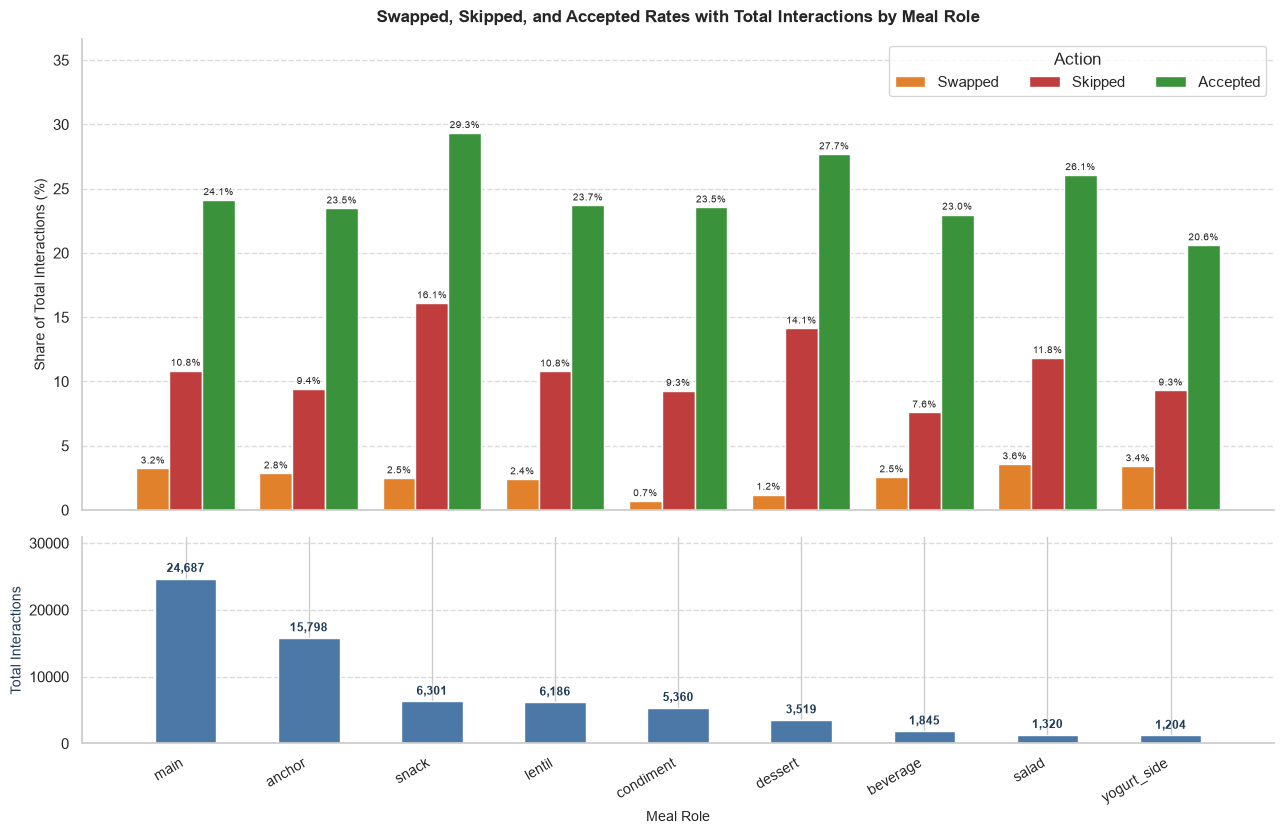

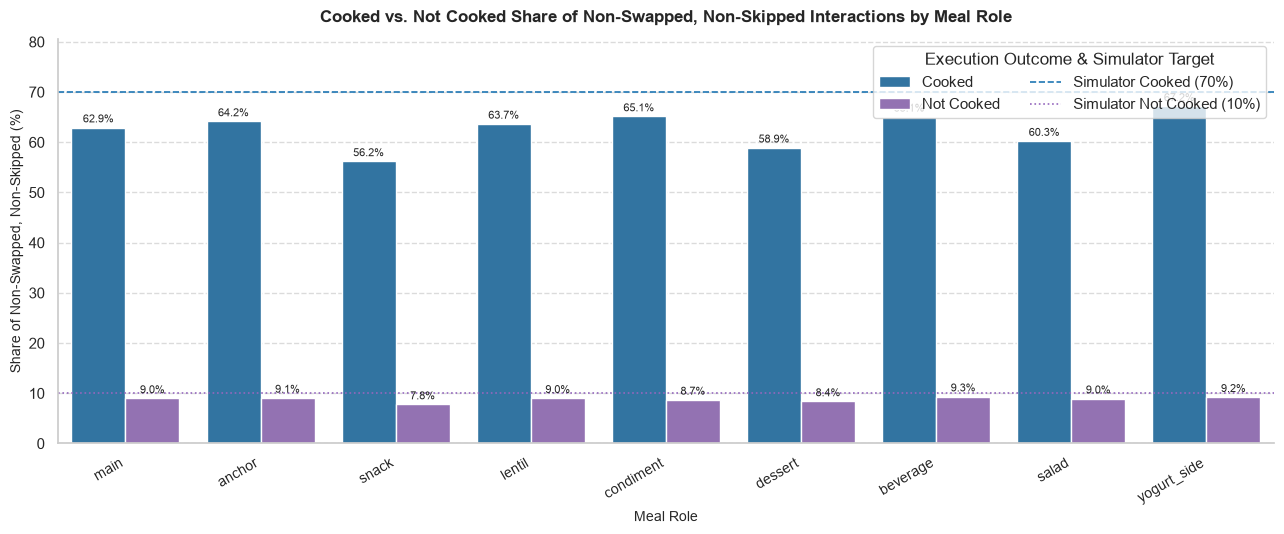

In [2]:
# Load recipe performance metrics from v_recipe_performance
query_recipe_perf = "SELECT * FROM v_recipe_performance;"
df_recipe_perf = pd.read_sql(query_recipe_perf, engine)

# Set default values if count columns are missing
count_defaults = {
    "total_interactions": 0,
    "cooked_count": 0,
    "accepted_count": 0,
    "not_cooked_count": 0,
    "swapped_count": 0,
    "skipped_count": 0,
}

rate_to_count = {
    "cook_rate_pct": "cooked_count",
    "acceptance_rate_pct": "accepted_count",
    "not_cooked_rate_pct": "not_cooked_count",
    "swap_rate_pct": "swapped_count",
    "skip_rate_pct": "skipped_count",
}

for col, default_val in count_defaults.items():
    if col not in df_recipe_perf.columns:
        df_recipe_perf[col] = default_val

# Compute counts from rate columns when count columns are all zero
for rate_col, count_col in rate_to_count.items():
    if df_recipe_perf[count_col].eq(0).all() and rate_col in df_recipe_perf.columns:
        df_recipe_perf[count_col] = (
            df_recipe_perf["total_interactions"] * df_recipe_perf[rate_col] / 100.0
        )

# Aggregate interaction counts by meal_role
df_meal_role = (
    df_recipe_perf.groupby("meal_role", as_index=False)
    .agg(
        total_interactions=("total_interactions", "sum"),
        cooked_count=("cooked_count", "sum"),
        accepted_count=("accepted_count", "sum"),
        not_cooked_count=("not_cooked_count", "sum"),
        swapped_count=("swapped_count", "sum"),
        skipped_count=("skipped_count", "sum"),
    )
    .sort_values("total_interactions", ascending=False)
)

# Calculate share of total interactions for Graph 1 actions
for outcome, count_col in [
    ("Swapped", "swapped_count"),
    ("Skipped", "skipped_count"),
    ("Accepted", "accepted_count"),
]:
    df_meal_role[f"{outcome}_pct"] = np.where(
        df_meal_role["total_interactions"] > 0,
        100.0 * df_meal_role[count_col] / df_meal_role["total_interactions"],
        0.0,
    )

# Calculate share of non-swapped, non-skipped interactions for Graph 2
non_action_base = (
    df_meal_role["cooked_count"]
    + df_meal_role["accepted_count"]
    + df_meal_role["not_cooked_count"]
)
df_meal_role["Cooked_of_non_skip_swap_pct"] = np.where(
    non_action_base > 0,
    100.0 * df_meal_role["cooked_count"] / non_action_base,
    0.0,
)
df_meal_role["Not_Cooked_of_non_skip_swap_pct"] = np.where(
    non_action_base > 0,
    100.0 * df_meal_role["not_cooked_count"] / non_action_base,
    0.0,
)

display(df_meal_role)

# --- Graph 1: Swapped, Skipped, Accepted, and Total Interactions ---
choice_cols = ["Swapped_pct", "Skipped_pct", "Accepted_pct"]
df_choice = df_meal_role.melt(
    id_vars=["meal_role"],
    value_vars=choice_cols,
    var_name="action",
    value_name="percentage",
)
df_choice["action"] = df_choice["action"].str.replace("_pct", "", regex=False)

choice_palette = {
    "Swapped": "#ff7f0e",
    "Skipped": "#d62728",
    "Accepted": "#2ca02c",
}

fig1, (ax1_top, ax1_bot) = plt.subplots(
    2,
    1,
    sharex=True,
    figsize=(13, 8.5),
    gridspec_kw={"height_ratios": [3.2, 1.4]},
)

sns.barplot(
    data=df_choice,
    x="meal_role",
    y="percentage",
    hue="action",
    palette=choice_palette,
    ax=ax1_top,
)

max_choice = df_choice["percentage"].max() if not df_choice.empty else 40
ax1_top.set_title(
    "Swapped, Skipped, and Accepted Rates with Total Interactions by Meal Role",
    fontsize=12,
    weight="bold",
    pad=12,
)
ax1_top.set_ylabel("Share of Total Interactions (%)", fontsize=10)
ax1_top.set_ylim(0, max(max_choice * 1.25, 35))
ax1_top.legend(title="Action", frameon=True, loc="upper right", ncol=3)
ax1_top.grid(axis="y", linestyle="--", alpha=0.7)
sns.despine(ax=ax1_top)

for p in ax1_top.patches:
    h = p.get_height()
    if h > 0:
        ax1_top.annotate(
            f"{h:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            fontsize=7.5,
            xytext=(0, 2),
            textcoords="offset points",
        )

bars1 = ax1_bot.bar(
    df_meal_role["meal_role"],
    df_meal_role["total_interactions"],
    color="#4c78a8",
    width=0.5,
)
ax1_bot.set_ylabel("Total Interactions", fontsize=10, color="#1f3b57")
ax1_bot.set_xlabel("Meal Role", fontsize=10)
ax1_bot.set_ylim(0, max(df_meal_role["total_interactions"].max() * 1.25, 1))
ax1_bot.grid(axis="y", linestyle="--", alpha=0.7)
sns.despine(ax=ax1_bot)

for bar in bars1:
    total = bar.get_height()
    ax1_bot.annotate(
        f"{int(total):,}",
        (bar.get_x() + bar.get_width() / 2.0, total),
        ha="center",
        va="bottom",
        fontsize=8.5,
        fontweight="bold",
        color="#1f3b57",
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

# --- Graph 2: Cooked vs. Not Cooked as Share of Non-Swapped, Non-Skipped ---
exec_cols = ["Cooked_of_non_skip_swap_pct", "Not_Cooked_of_non_skip_swap_pct"]
df_exec = df_meal_role.melt(
    id_vars=["meal_role"],
    value_vars=exec_cols,
    var_name="outcome",
    value_name="percentage",
)
df_exec["outcome"] = df_exec["outcome"].map(
    {
        "Cooked_of_non_skip_swap_pct": "Cooked",
        "Not_Cooked_of_non_skip_swap_pct": "Not Cooked",
    }
)

exec_palette = {
    "Cooked": "#1f77b4",
    "Not Cooked": "#9467bd",
}

fig2, ax2 = plt.subplots(figsize=(13, 5.5))

sns.barplot(
    data=df_exec,
    x="meal_role",
    y="percentage",
    hue="outcome",
    palette=exec_palette,
    ax=ax2,
)

# Add reference lines for the 70% cooked and 10% not_cooked simulator thresholds
ax2.axhline(70, color="#1f77b4", linestyle="--", linewidth=1.2, label="Simulator Cooked (70%)")
ax2.axhline(10, color="#9467bd", linestyle=":", linewidth=1.2, label="Simulator Not Cooked (10%)")

max_exec = df_exec["percentage"].max() if not df_exec.empty else 75
ax2.set_title(
    "Cooked vs. Not Cooked Share of Non-Swapped, Non-Skipped Interactions by Meal Role",
    fontsize=12,
    weight="bold",
    pad=12,
)
ax2.set_ylabel("Share of Non-Swapped, Non-Skipped (%)", fontsize=10)
ax2.set_xlabel("Meal Role", fontsize=10)
ax2.set_ylim(0, max(max_exec * 1.2, 80))
ax2.legend(title="Execution Outcome & Simulator Target", frameon=True, loc="upper right", ncol=2)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
sns.despine(ax=ax2)

for p in ax2.patches:
    h = p.get_height()
    if h > 0:
        ax2.annotate(
            f"{h:.1f}%",
            (p.get_x() + p.get_width() / 2.0, h),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 2),
            textcoords="offset points",
        )

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.tight_layout()
plt.show()

## 2. Most Common Swap Pairs ($A \rightarrow B$ Transitions)
Analyzing the `v_common_swap_pairs` view to identify which dishes users frequently swap away from and what they substitute them with.

,transition_label,transition_count,original_meal_role
0,Carrot Kosumalli → Kosambari [salad],2,salad
1,Kosambari → Carrot Kosumalli [salad],2,salad
2,Menthya Soppu Saaru → Arachuvitta Sambar [lentil],2,lentil
3,Cheera Salad → Green Salad [salad],2,salad
4,Chicken Tikka → Aloo Posto [main],2,main
5,Muttai Podimas → Meen Kuzhambu [main],2,main
6,Mango Curry → Fansi nu Shaak [main],2,main
7,Jigarthanda → Buttermilk [beverage],2,beverage


,label,net_swap_score
577,Filter Coffee [beverage],-7.0
685,Clam Stir Fry [main],-7.0
131,Beetroot Thoran [main],-7.0
67,Kozhi Rasam [main],-6.0
94,Tomato Uttapam [anchor],-6.0
15,Beans Vepudu [main],5.0
104,Stuffed Ivy Gourd [main],6.0
140,Chettinad Pepper Chicken [main],6.0
56,Green Salad [salad],6.0
226,Vangi Bath [anchor],7.0


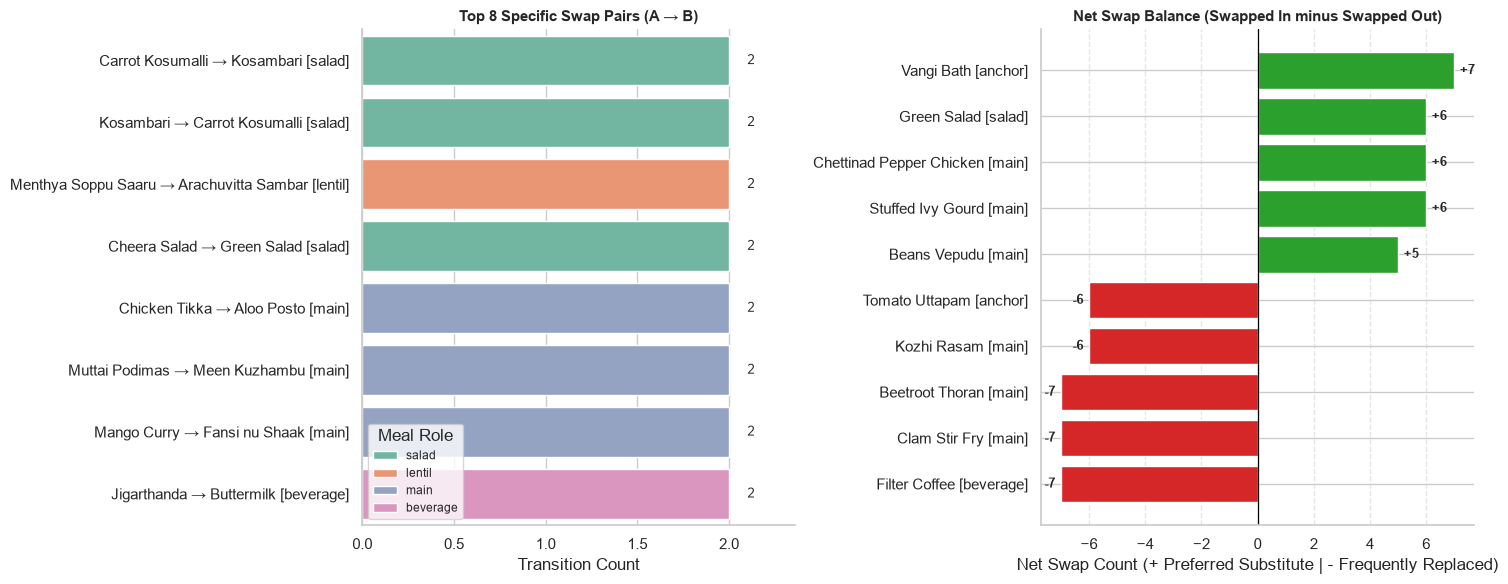

In [6]:
# Query top swap pairs
query_swap_pairs = "SELECT * FROM v_common_swap_pairs;"
df_swap_pairs = pd.read_sql(query_swap_pairs, engine)

# Calculate net swap score per recipe across all recorded transitions
out_counts = df_swap_pairs.groupby(['original_recipe_code', 'original_recipe_name', 'original_meal_role'])['transition_count'].sum().reset_index()
out_counts.columns = ['recipe_code', 'recipe_name', 'meal_role', 'swapped_out']

in_counts = df_swap_pairs.groupby(['swapped_to_recipe_code', 'swapped_to_recipe_name', 'swapped_to_meal_role'])['transition_count'].sum().reset_index()
in_counts.columns = ['recipe_code', 'recipe_name', 'meal_role', 'swapped_in']

df_net_recipes = pd.merge(out_counts, in_counts, on=['recipe_code', 'recipe_name', 'meal_role'], how='outer').fillna(0)
df_net_recipes['net_swap_score'] = df_net_recipes['swapped_in'] - df_net_recipes['swapped_out']
df_net_recipes['label'] = df_net_recipes['recipe_name'] + ' [' + df_net_recipes['meal_role'] + ']'

# Select top 5 most "Swapped Into" (Favorites) and top 5 most "Swapped Out Of" (Rejected)
top_gainers = df_net_recipes.nlargest(5, 'net_swap_score')
top_losers = df_net_recipes.nsmallest(5, 'net_swap_score')
df_extremes = pd.concat([top_gainers, top_losers]).drop_duplicates().sort_values('net_swap_score', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Top 8 Specific Pair Transitions
top_swaps = df_swap_pairs.head(8).copy()
top_swaps['transition_label'] = (
    top_swaps['original_recipe_name'] + ' → ' + top_swaps['swapped_to_recipe_name'] +
    ' [' + top_swaps['original_meal_role'] + ']'
)

display(top_swaps[['transition_label', 'transition_count', 'original_meal_role']])
display(df_extremes[['label', 'net_swap_score']])

sns.barplot(
    data=top_swaps,
    x='transition_count',
    y='transition_label',
    hue='original_meal_role',
    dodge=False,
    palette='Set2',
    ax=ax1
)
ax1.set_title('Top 8 Specific Swap Pairs (A → B)', fontsize=11, weight='bold')
ax1.set_xlabel('Transition Count')
ax1.set_ylabel('')
ax1.set_xlim(0, top_swaps['transition_count'].max() * 1.18)
ax1.legend(title='Meal Role', loc='lower left', fontsize=8.5)
for p in ax1.patches:
    w = p.get_width()
    if w > 0:
        ax1.annotate(f'{int(w)}', (w + 0.1, p.get_y() + p.get_height()/2), va='center', fontsize=9)

# Panel 2: Diverging Bar Chart of Net Swap Gain/Loss
colors = ['#d62728' if x < 0 else '#2ca02c' for x in df_extremes['net_swap_score']]
ax2.barh(df_extremes['label'], df_extremes['net_swap_score'], color=colors)
ax2.axvline(0, color='black', linewidth=0.9)
ax2.set_title('Net Swap Balance (Swapped In minus Swapped Out)', fontsize=11, weight='bold')
ax2.set_xlabel('Net Swap Count (+ Preferred Substitute | - Frequently Replaced)')
ax2.grid(axis='x', linestyle='--', alpha=0.5)

for i, val in enumerate(df_extremes['net_swap_score']):
    offset = 0.2 if val >= 0 else -0.2
    ha = 'left' if val >= 0 else 'right'
    ax2.text(val + offset, i, f'{int(val):+d}', va='center', ha=ha, fontsize=9, fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

## 3. Plan-to-Order Conversion Rate by Template Goal
Evaluating the `v_template_goal_conversion` view to see how household health goals affect final grocery order conversion.

,template_goal,total_plans_created,total_orders_placed,conversion_rate_pct
0,weight-loss,1178,990,84.04
1,high-protein,1137,845,74.32
2,everyday,1141,729,63.89


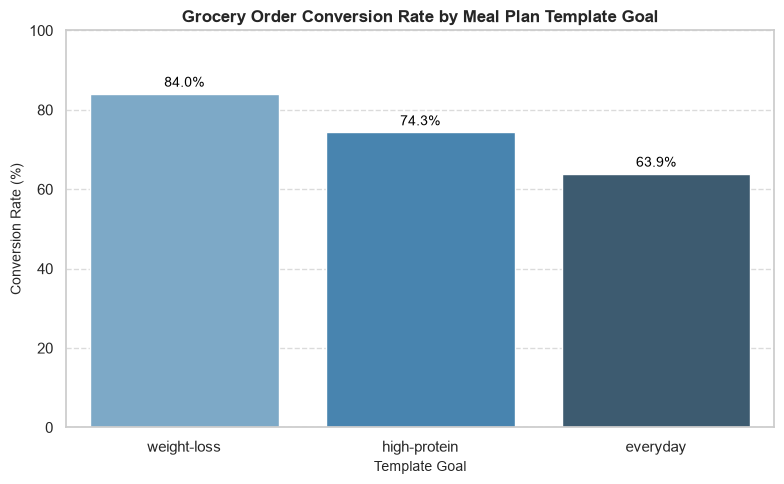

In [4]:
# Query plan-to-order conversion metrics grouped by template goal
query_conversion = "SELECT * FROM v_template_goal_conversion;"
df_conversion = pd.read_sql(query_conversion, engine)

display(df_conversion)

# Plot conversion rates across template goals
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_conversion,
    x='template_goal',
    y='conversion_rate_pct',
    palette='Blues_d',
    hue='template_goal',
    legend=False
)

plt.title(
    'Grocery Order Conversion Rate by Meal Plan Template Goal',
    fontsize=12,
    weight='bold',
)
plt.xlabel('Template Goal', fontsize=10)
plt.ylabel('Conversion Rate (%)', fontsize=10)
plt.ylim(0, 100)

# Add data labels on top of bars
for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}%',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=10,
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 4. Household Repeat-Dish Intervals
Analyzing the `v_household_repeat_intervals` view to examine household fatigue patterns and repetition frequency.

,avg_repeat_interval_days,min_repeat_interval_days,total_repeats_tracked
count,285.000000,285.000000,285.000000
mean,29.692632,3.684211,30.326316
std,6.783865,2.870184,11.159638
min,1.000000,0.000000,1.000000
25%,28.000000,2.000000,28.000000
50%,30.900000,3.000000,33.000000
75%,33.800000,5.000000,37.000000
max,42.900000,18.000000,50.000000


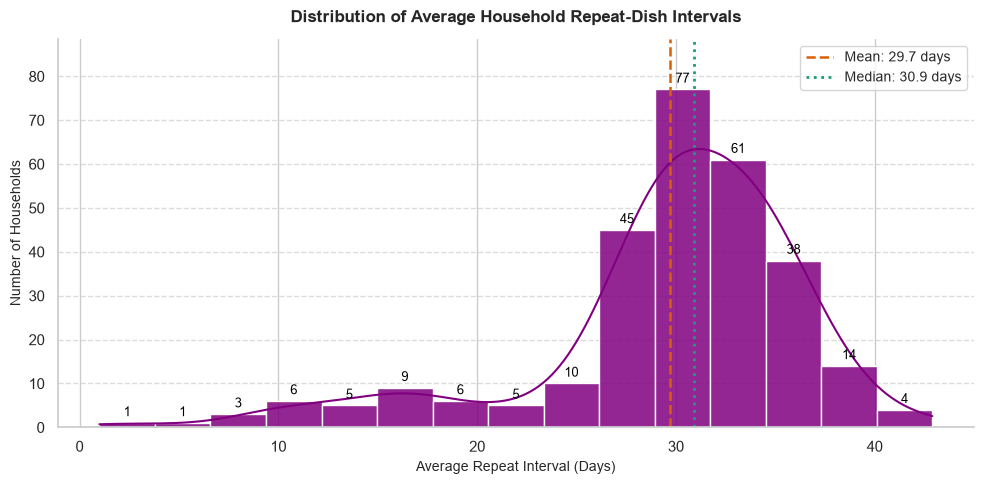

In [5]:
# Query household repeat intervals from the view
query_repeat_intervals = "SELECT * FROM v_household_repeat_intervals;"
df_repeat_intervals = pd.read_sql(query_repeat_intervals, engine)

display(df_repeat_intervals.describe())

# Plot distribution of average repeat intervals across households
plt.figure(figsize=(10, 5))
ax = sns.histplot(
    data=df_repeat_intervals,
    x='avg_repeat_interval_days',
    bins=15,
    kde=True,
    color='purple',
    edgecolor='white',
    alpha=0.85
)

# Calculate mean and median for reference lines
mean_val = df_repeat_intervals['avg_repeat_interval_days'].mean()
median_val = df_repeat_intervals['avg_repeat_interval_days'].median()

plt.axvline(mean_val, color='#d95f02', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.1f} days')
plt.axvline(median_val, color='#1b9e77', linestyle=':', linewidth=2.0, label=f'Median: {median_val:.1f} days')

plt.title('Distribution of Average Household Repeat-Dish Intervals', fontsize=12, weight='bold', pad=12)
plt.xlabel('Average Repeat Interval (Days)', fontsize=10)
plt.ylabel('Number of Households', fontsize=10)

# Add count labels above non-empty histogram bars
max_height = max([p.get_height() for p in ax.patches])
plt.ylim(0, max_height * 1.15)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(frameon=True, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.despine()
plt.tight_layout()
plt.show()